Results for ../results/gemma:7b_Strategy_5_Contextual_Prompting.npy:
  Precision: 0.7500
  Recall: 0.6000
  F1 Score: 0.6667
  SHD (Structural Hamming Distance): 6.0000
  FDR False Discovery Rate): 0.2500
  Pearson Correlation: 0.5983
  Hamming Distance: 0.1224
  Frobenius Norm: 2.4495

Evaluation Metrics Table:
                                    Precision  Recall  F1 Score  \
gemma:7b_Strategy_4_Style_Promting       0.75     0.6  0.666667   

                                    SHD (Structural Hamming Distance)  \
gemma:7b_Strategy_4_Style_Promting                                  6   

                                    FDR False Discovery Rate)  \
gemma:7b_Strategy_4_Style_Promting                       0.25   

                                    Pearson Correlation  Hamming Distance  \
gemma:7b_Strategy_4_Style_Promting             0.598335          0.122449   

                                    Frobenius Norm  
gemma:7b_Strategy_4_Style_Promting         2.44949  


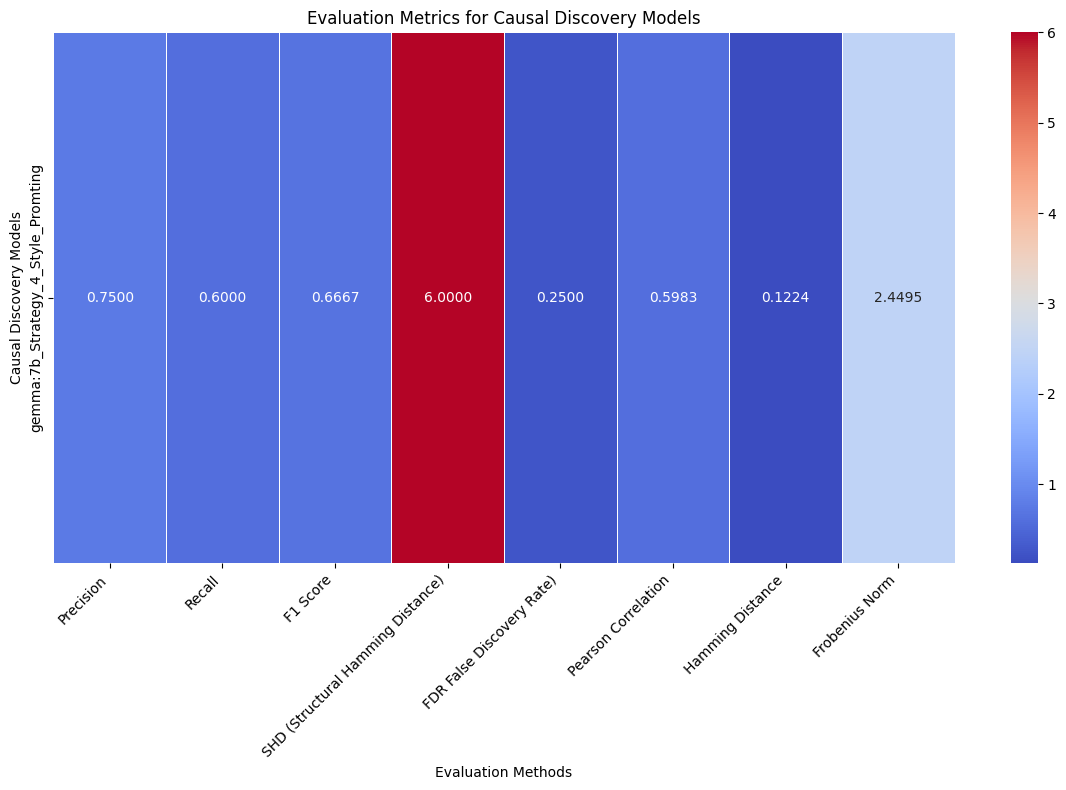

In [52]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score
from scipy.spatial.distance import hamming
from scipy.linalg import norm
from scipy.stats import pearsonr

# Define the file paths for the adjacency matrices
file_paths = [
    "../results/gemma:7b_Strategy_5_Style_Prompting.npy"
]

# Load the ground truth adjacency matrix
ground_truth_path = "../results/Ground_Truth_UC_EV_Energy_Consumption_adjacency_matrix.npy"
ground_truth = np.load(ground_truth_path)

# Function to compute Structural Hamming Distance (SHD)
def compute_shd(matrix1, matrix2):
    return np.sum(matrix1 != matrix2)

# Function to compute False Discovery Rate (FDR)
def compute_fdr(predicted, ground_truth):
    false_positives = np.sum((predicted == 1) & (ground_truth == 0))
    total_predicted = np.sum(predicted == 1)
    return false_positives / total_predicted if total_predicted > 0 else 0

# Initialize a dictionary to store the results
results = {}

# Iterate through each adjacency matrix file
for file_path in file_paths:
    # Load the predicted adjacency matrix
    predicted = np.load(file_path)
    
    # Binarize the matrices using a threshold (e.g., 0.5)
    ground_truth_binary = (ground_truth > 0.5).astype(int)
    predicted_binary = (predicted > 0.5).astype(int)
    
    # Ensure the matrices have the same shape
    if ground_truth.shape != predicted.shape:
        print(f"Shape mismatch: ground_truth {ground_truth.shape}, predicted {predicted.shape}")
        min_dim = min(ground_truth.shape[0], predicted.shape[0])
        ground_truth = ground_truth[:min_dim, :min_dim]
        predicted = predicted[:min_dim, :min_dim]
        ground_truth_binary = (ground_truth > 0.5).astype(int)
        predicted_binary = (predicted > 0.5).astype(int)
    
    # Flatten the matrices for metric calculations
    ground_truth_flat = ground_truth_binary.flatten()
    predicted_flat = predicted_binary.flatten()
    
    # Compute evaluation metrics
    precision = precision_score(ground_truth_flat, predicted_flat, zero_division=0)
    recall = recall_score(ground_truth_flat, predicted_flat, zero_division=0)
    f1 = f1_score(ground_truth_flat, predicted_flat, zero_division=0)
    shd = compute_shd(predicted, ground_truth)
    fdr = compute_fdr(predicted, ground_truth)
    pearson_corr, _ = pearsonr(ground_truth_flat, predicted_flat)
    hamming_dist = hamming(ground_truth_flat, predicted_flat)
    frobenius_norm = norm(predicted - ground_truth, 'fro')
        
    # Store the results
    results[file_path] = {
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "SHD (Structural Hamming Distance)": shd,
        "FDR False Discovery Rate)": fdr,
        "Pearson Correlation": pearson_corr,
        "Hamming Distance": hamming_dist,
        "Frobenius Norm": frobenius_norm
    }

# Display the results
for file_path, metrics in results.items():
    print(f"Results for {file_path}:")
    for metric, value in metrics.items():
        print(f"  {metric}: {value:.4f}")
    print()
    
# Convert the results dictionary into a pandas DataFrame
results_df = pd.DataFrame.from_dict(results, orient='index')

# Rename the index to represent the causal discovery models
results_df.index = [
    "gemma:7b_Strategy_4_Style_Promting"
]

# Display the DataFrame
print("Evaluation Metrics Table:")
print(results_df)

# Plot a heatmap for better visualization
plt.figure(figsize=(12, 8))
sns.heatmap(results_df, annot=True, fmt=".4f", cmap="coolwarm", cbar=True, linewidths=0.5)
plt.title("Evaluation Metrics for Causal Discovery Models")
plt.xlabel("Evaluation Methods")
plt.ylabel("Causal Discovery Models")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()